# OP-FL v2 — 04. Caractérisation de l'observation du label (sans entraînement)

**Question.** Dans eICU, l'observation du label dépend-elle de la politique de chaque hôpital, assez pour biaiser ce qu'un modèle fédéré apprend ?
Ce notebook n'entraîne aucun modèle de prédiction : il décrit le phénomène et décide, avec des critères fixés à l'avance, si l'on passe aux expériences d'entraînement (notebook 05).

**Deux labels comparés**

| Label | Examen | Type d'examen | Définition | Observé si |
|---|---|---|---|---|
| AKI | créatinine | de routine | pic sur [24 h, 7 j] / minimum sur [0, 24 h[ ≥ 2 | créatinine redosée après 24 h |
| Hyperlactatémie | lactate | prescrit sur suspicion | maximum sur [24 h, 72 h] ≥ 4 mmol/L | lactate redosé après 24 h |

Pour chacun, deux codages : **cas complets** (label défini seulement si l'examen est redosé) et **« non dosé = négatif »** (convention fréquente, celle de Chang et al. 2022).

**Population.** Les 60 hôpitaux de développement uniquement (le test verrouillé n'est pas touché), séjours **encore en réanimation à 48 h** :
eICU ne contient les examens que pendant le séjour en réanimation, donc un patient sorti à 30 h n'a pas pu être redosé ; ce n'est pas une décision de ne pas tester.

**Critères fixés avant les résultats** (étape 8)

| Code | Question | Mesure | Seuil |
|---|---|---|---|
| **C1** | L'observation du label dépend-elle de l'hôpital, à patient comparable ? | écart-type τ entre hôpitaux du décalage de propension (log-odds), méta-analyse | τ ≥ 0,25 et test Q p < 0,001 (créatinine) |
| **C2** | Dépend-elle du patient ? | AUROC de P(redosage \| données des 24 premières heures) sur val + test | ≥ 0,65 (créatinine) |
| **C3** | Le label change-t-il avec la seule politique de mesure ? | éclaircissement des dosages des hôpitaux qui dosent le plus vers la fréquence de ceux qui dosent le moins : baisse relative des AKI détectées | ≥ 10 % |
| **C4** | Les hôpitaux qui dosent plus trouvent-ils plus d'AKI que prévu ? | Spearman entre log(observé / attendu) et intensité de dosage, par hôpital | ρ ≥ 0,3 et p < 0,05 |
| **C5** | L'effet est-il plus fort pour un examen sur suspicion ? | τ et AUROC du lactate comparés à ceux de la créatinine | descriptif |

* **GO** (notebook 05, entraînement fédéré) : C1 et (C3 ou C4) → les hôpitaux n'observent pas le label de la même façon, et cela change le label lui-même.
* **PARTIEL** : (C3 ou C4) sans C1 → le label dépend de la politique de mesure, mais les hôpitaux se ressemblent ; l'intérêt fédéré est plus faible.
* **NO-GO** : sinon.

**C2** ne bloque pas la décision : il dit quel mécanisme le notebook 05 doit traiter.
Si le redosage dépend du patient (C2 rempli), l'analyse en cas complets est biaisée (label **manquant** non aléatoire) en plus du label **erroné** ; sinon, seul le label erroné compte.

## Étape 0 — Configuration

`EICU_DIR` doit pointer vers le même dossier que dans le notebook 01 (la table `lab` brute est relue pour les dosages après 24 h).

In [1]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION
# ============================================================
import sys, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 200)

EICU_DIR = Path("../../../dataset")   # même valeur que dans la cellule 0 du notebook 01
PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
INTERIM, SPLITS = DATA_DIR / "interim", DATA_DIR / "splits"
SRC_DIR = PROJECT_DIR / "src"
RES_DIR = PROJECT_DIR / "results" / "04_observation_label"
FIG_DIR = RES_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((SPLITS / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."
DEV = sorted(int(h) for k in protocol["folds"] for h in protocol["folds"][k])
LOCKED = set(protocol["locked_test_hospitals"])

def table_path(name):
    for ext in (".csv.gz", ".csv"):
        p = EICU_DIR / f"{name}{ext}"
        if p.exists():
            return p
    raise FileNotFoundError(f"Table '{name}' introuvable dans {EICU_DIR.resolve()}")
table_path("lab")

# ---------- Définitions (fixées avant les résultats) ----------
WIN = 1440                       # fin de la fenêtre des données d'entrée (24 h)
PRESENT_MIN = 2880               # population : encore en réanimation à 48 h
AKI_END = 7 * 1440               # créatinine cherchée sur [24 h, 7 j]
AKI_RATIO = 2.0                  # KDIGO stade >= 2 simplifié
LAC_END = 3 * 1440               # lactate cherché sur [24 h, 72 h]
LAC_THR = 4.0                    # hyperlactatémie sévère (mmol/L)
BOUNDS = {"creatinine": (0.1, 25.0), "lactate": (0.1, 30.0)}
POLICIES_H = {"creatinine": [12, 24, 48, 72], "lactate": [12, 24, 48]}
N_REP = 20                       # répétitions de l'éclaircissement aléatoire
SEED = 2026
CRIT = {"C1_tau": 0.25, "C1_p": 0.001, "C2_auroc": 0.65, "C3_drop": 0.10, "C4_rho": 0.30, "C4_p": 0.05}
(RES_DIR / "config.json").write_text(json.dumps(
    {"present_min": PRESENT_MIN, "aki_end": AKI_END, "aki_ratio": AKI_RATIO, "lac_end": LAC_END,
     "lac_thr": LAC_THR, "policies_h": POLICIES_H, "n_rep": N_REP, "criteria": CRIT,
     "protocol_hash": protocol["hash"]}, indent=2), encoding="utf-8")
print(f"{len(DEV)} hôpitaux de développement | protocole {protocol['hash']}")

60 hôpitaux de développement | protocole d92099ea7c11d517


## Étape 1 — Module `src/opfl_label.py`

Fonctions réutilisées au notebook 05 : construction des labels à partir des dosages, décalage de propension propre à un site, éclaircissement des dosages.

In [ ]:
# %%writefile ../src/opfl_label.py
# """
# opfl_label — observation du label (OP-FL).

# Généré par notebooks/04_observation_label.ipynb (étape 1) : modifier le notebook, pas ce fichier.

# - summarize_post : nombre de dosages et pic par séjour dans une fenêtre d'observation.
# - aki_labels / threshold_labels : labels en cas complets et en « non dosé = négatif ».
# - site_offset : décalage (log-odds) d'un site par rapport à une propension commune, et sa variance.
# - thin_interval / thin_bernoulli : éclaircissement des dosages (politique « au plus un dosage toutes les H heures »,
#   ou conservation aléatoire avec une probabilité par séjour).
# """
# import numpy as np
# import pandas as pd


# def summarize_post(post, stays):
#     """post : DataFrame [stay_id, offset, value] déjà restreint à la fenêtre ; stays : index des séjours."""
#     g = post.groupby("stay_id")["value"]
#     out = pd.DataFrame({"n_post": g.size(), "peak": g.max()}).reindex(stays)
#     out["n_post"] = out["n_post"].fillna(0).astype(int)
#     return out


# def aki_labels(base, peak, n_post, ratio=2.0):
#     """Cas complets : défini si créatinine de base et redosage ; « non dosé = négatif » : défini si base."""
#     base, peak, n_post = np.asarray(base, float), np.asarray(peak, float), np.asarray(n_post)
#     has_base = ~np.isnan(base)
#     obs = (n_post > 0) & has_base
#     with np.errstate(divide="ignore", invalid="ignore"):
#         pos = peak / base >= ratio
#     cc = np.where(obs, pos.astype(float), np.nan)
#     neg = np.where(has_base, np.where(obs, pos.astype(float), 0.0), np.nan)
#     return obs, cc, neg


# def threshold_labels(peak, n_post, thr):
#     peak, n_post = np.asarray(peak, float), np.asarray(n_post)
#     obs = n_post > 0
#     pos = np.nan_to_num(peak, nan=-np.inf) >= thr
#     return obs, np.where(obs, pos.astype(float), np.nan), np.where(obs, pos.astype(float), 0.0)


# def site_offset(lp, d, max_iter=100):
#     """a tel que somme(sigmoid(lp + a)) = somme(d) (d borné à [0,5 ; n - 0,5]) ; variance = 1 / information."""
#     lp, d = np.asarray(lp, float), np.asarray(d, float)
#     n = len(d)
#     target = float(np.clip(d.sum(), 0.5, n - 0.5))
#     a = 0.0
#     for _ in range(max_iter):
#         mu = 1.0 / (1.0 + np.exp(-np.clip(lp + a, -30, 30)))
#         step = (mu.sum() - target) / max((mu * (1 - mu)).sum(), 1e-9)
#         a -= step
#         if abs(step) < 1e-9:
#             break
#     mu = 1.0 / (1.0 + np.exp(-np.clip(lp + a, -30, 30)))
#     return float(a), float(1.0 / max((mu * (1 - mu)).sum(), 1e-9))


# def thin_interval(post, hours, start=1440):
#     """Garde le premier dosage de chaque tranche de H heures à partir de `start`."""
#     b = ((post["offset"] - start) // (60 * hours)).astype(int)
#     return (post.assign(_b=b).sort_values(["stay_id", "offset"], kind="stable")
#                 .drop_duplicates(["stay_id", "_b"]).drop(columns="_b"))


# def thin_bernoulli(post, keep_prob, rng):
#     """keep_prob : probabilité de conserver chaque dosage (tableau aligné sur post)."""
#     return post[rng.random(len(post)) < np.asarray(keep_prob, float)]

## Étape 2 — Dosages de créatinine et de lactate jusqu'à 7 jours

Un passage sur `lab.csv.gz` : créatinine sur [0, 7 j], lactate sur [0, 72 h], pour les séjours de la cohorte. Mêmes bornes de plausibilité que le notebook 01.

In [2]:
# ============================================================
# ÉTAPE 2 — EXTRACTION DES DOSAGES (CRÉATININE 0–7 j, LACTATE 0–72 h)
# ============================================================
cohort = pd.read_parquet(INTERIM / "cohort_final.parquet")
STAY_IDS = cohort["patientunitstayid"].to_numpy()
END = {"creatinine": AKI_END, "lactate": LAC_END}
rows, t0 = [], time.time()
for i, ch in enumerate(pd.read_csv(table_path("lab"), usecols=["patientunitstayid", "labresultoffset", "labname", "labresult"],
                                   chunksize=2_000_000, low_memory=False)):
    ch = ch[ch["labname"].isin(list(END)) & ch["labresult"].notna() & ch["patientunitstayid"].isin(STAY_IDS)]
    ch = ch[(ch["labresultoffset"] >= 0) & (ch["labresultoffset"] <= ch["labname"].map(END))]
    lo, hi = ch["labname"].map({k: v[0] for k, v in BOUNDS.items()}), ch["labname"].map({k: v[1] for k, v in BOUNDS.items()})
    ch = ch[(ch["labresult"] >= lo) & (ch["labresult"] <= hi)]
    rows.append(ch.rename(columns={"patientunitstayid": "stay_id", "labname": "var",
                                   "labresultoffset": "offset", "labresult": "value"}))
    print(f"  lab : bloc {i + 1} ({time.time() - t0:.0f} s)", end="\r")
labs = pd.concat(rows, ignore_index=True)[["stay_id", "var", "offset", "value"]]
labs.to_parquet(RES_DIR / "label_labs.parquet", index=False)
print(f"\nDosages extraits en {time.time() - t0:.0f} s :")
display(labs.assign(apres_24h=labs["offset"] >= WIN).groupby(["var", "apres_24h"]).size().unstack())

  lab : bloc 20 (58 s)
Dosages extraits en 59 s :


apres_24h,False,True
var,,
creatinine,139341,319164
lactate,47691,20795


## Étape 3 — Labels et observation, par séjour

Pour chaque séjour des hôpitaux de développement : présence à 48 h, créatinine de base, nombre de redosages après 24 h (fenêtre arrêtée à la sortie de réanimation), intensité de dosage (dosages par jour de présence), et les deux codages de chaque label.
Contrôle : le label AKI recalculé doit coïncider avec celui du notebook 01.

In [3]:
# ============================================================
# ÉTAPE 3 — LABELS ET OBSERVATION PAR SÉJOUR
# ============================================================
import opfl_data as od, opfl_metrics, opfl_label
for m in (od, opfl_metrics, opfl_label):
    importlib.reload(m)
from opfl_label import summarize_post, aki_labels, threshold_labels, site_offset, thin_interval, thin_bernoulli
from opfl_metrics import auroc, random_effects

splits = pd.read_parquet(SPLITS / "patient_splits.parquet")[["patientunitstayid", "split"]]
c = (cohort.merge(splits, on="patientunitstayid").rename(columns={"patientunitstayid": "stay_id"}))
c = c[c["hospitalid"].isin(DEV)].sort_values("stay_id").reset_index(drop=True)
c["present48"] = c["unitdischargeoffset"] >= PRESENT_MIN
disc = c.set_index("stay_id")["unitdischargeoffset"]
labs = pd.read_parquet(RES_DIR / "label_labs.parquet")
labs = labs[labs["stay_id"].isin(c["stay_id"])]

def post_window(var, end):
    x = labs[labs["var"] == var]
    stop = np.minimum(x["stay_id"].map(disc), end)
    return x[(x["offset"] >= WIN) & (x["offset"] <= stop)][["stay_id", "offset", "value"]]

POST = {"creatinine": post_window("creatinine", AKI_END), "lactate": post_window("lactate", LAC_END)}
cr = labs[labs["var"] == "creatinine"]
base = cr[cr["offset"] < WIN].groupby("stay_id")["value"].min().reindex(c["stay_id"])

s_cr = summarize_post(POST["creatinine"], c["stay_id"])
c["cr_base"] = base.to_numpy()
c["cr_n_post"], c["cr_peak"] = s_cr["n_post"].to_numpy(), s_cr["peak"].to_numpy()
c["obs_cr"], c["aki_cc"], c["aki_neg"] = aki_labels(c["cr_base"], c["cr_peak"], c["cr_n_post"], AKI_RATIO)
c["cr_days"] = (np.minimum(c["unitdischargeoffset"], AKI_END) - WIN).clip(lower=1) / 1440
c["cr_rate"] = c["cr_n_post"] / c["cr_days"]

s_la = summarize_post(POST["lactate"], c["stay_id"])
c["la_n_post"], c["la_peak"] = s_la["n_post"].to_numpy(), s_la["peak"].to_numpy()
c["obs_la"], c["hyper_cc"], c["hyper_neg"] = threshold_labels(c["la_peak"], c["la_n_post"], LAC_THR)
c["la_days"] = (np.minimum(c["unitdischargeoffset"], LAC_END) - WIN).clip(lower=1) / 1440
c["la_rate"] = c["la_n_post"] / c["la_days"]
c.to_parquet(RES_DIR / "stay_labels.parquet", index=False)

# contrôle de cohérence avec le notebook 01 (qui ne coupe pas la fenêtre à la sortie de réanimation)
oc = pd.read_parquet(INTERIM / "outcomes.parquet").set_index("patientunitstayid").loc[c["stay_id"]]
peak_nb01 = cr[cr["offset"] >= WIN].groupby("stay_id")["value"].max().reindex(c["stay_id"]).to_numpy()
same_extraction = bool(np.allclose(np.nan_to_num(peak_nb01, nan=-1), np.nan_to_num(oc["cr_peak"].to_numpy(), nan=-1))
                       and np.allclose(np.nan_to_num(c["cr_base"], nan=-1), np.nan_to_num(oc["cr_base"].to_numpy(), nan=-1)))
both = oc["aki_ascertained"].to_numpy() & c["obs_cr"].to_numpy()
agree_aki = float((oc["y_aki"].to_numpy()[both] == c["aki_cc"].to_numpy()[both]).mean())
print(f"Extraction identique au notebook 01 (base et pic sans coupure à la sortie) : {same_extraction}")
print(f"Accord du label AKI avec le notebook 01 (fenêtre coupée à la sortie de réanimation) : {agree_aki:.2%}")

P = c[c["present48"]]
flow = pd.DataFrame({
    "séjours": [len(c), int(c["present48"].sum()), int(P["cr_base"].notna().sum())],
    "créatinine redosée après 24 h": [c["obs_cr"].mean(), P["obs_cr"].mean(), P.loc[P["cr_base"].notna(), "obs_cr"].mean()],
    "lactate redosé après 24 h": [c["obs_la"].mean(), P["obs_la"].mean(), np.nan],
}, index=["tous les séjours de dév.", "présents à 48 h", "présents à 48 h avec créatinine de base"])
display(flow.round(3))
summary = pd.DataFrame({
    "AKI (cas complets)": [np.nanmean(P["aki_cc"])], "AKI (non dosé = négatif)": [np.nanmean(P["aki_neg"])],
    "hyperlactatémie (cas complets)": [np.nanmean(P["hyper_cc"])], "hyperlactatémie (non dosé = négatif)": [np.nanmean(P["hyper_neg"])],
    "dosages de créatinine / jour (moy.)": [P["cr_rate"].mean()], "dosages de lactate / jour (moy.)": [P["la_rate"].mean()]}, index=["présents à 48 h"])
display(summary.T.round(4))

Extraction identique au notebook 01 (base et pic sans coupure à la sortie) : True
Accord du label AKI avec le notebook 01 (fenêtre coupée à la sortie de réanimation) : 99.48%


,séjours,créatinine redosée après 24 h,lactate redosé après 24 h
tous les séjours de dév.,66094,0.687,0.108
présents à 48 h,38278,0.897,0.161
présents à 48 h avec créatinine de base,35814,0.959,NaN


,présents à 48 h
AKI (cas complets),0.0442
AKI (non dosé = négatif),0.0424
hyperlactatémie (cas complets),0.1526
hyperlactatémie (non dosé = négatif),0.0246
dosages de créatinine / jour (moy.),1.1235
dosages de lactate / jour (moy.),0.1929


## Étape 4 — Variables des 24 premières heures

Résumé de chaque séjour à 24 h, à partir des données V1.1 (normalisation du pli `final`, construite sur les seuls hôpitaux de développement) :
dernière valeur de chaque variable, fraction d'heures observées, nombre total de dosages, variables statiques.

In [4]:
# ============================================================
# ÉTAPE 4 — VARIABLES DES 24 PREMIÈRES HEURES
# ============================================================
norm = od.load_normalizer(DATA_DIR, "final")
feats = od.load_features(str(DATA_DIR))["features"]
parts = []
for h in DEV:
    cl = od.load_client(DATA_DIR, h, norm, mode="global")
    arr = np.concatenate([cl["X"][:, -1, :], cl["M"].mean(axis=1), cl["C"].sum(axis=1), cl["S"]], axis=1)
    parts.append(pd.DataFrame(arr, index=cl["stay_id"]))
FX = pd.concat(parts)
FX.columns = ([f"last_{v}" for v in feats] + [f"frac_{v}" for v in feats] + [f"count_{v}" for v in feats]
              + od.static_names(DATA_DIR, norm))
PHYS = [c_ for c_ in FX.columns if c_.startswith("last_")] + od.static_names(DATA_DIR, norm)   # sans M ni C
assert set(c["stay_id"]) <= set(FX.index)
print(f"{FX.shape[0]} séjours × {FX.shape[1]} variables ({len(PHYS)} sans les indicateurs d'observation)")

66094 séjours × 108 variables (50 sans les indicateurs d'observation)


## Étape 5 — Qui est redosé ? Propension d'observation du label (C1, C2, C5)

1. Un modèle **commun** (régression logistique, sans l'hôpital) prédit le redosage à partir de la **physiologie et des variables statiques** des 24 premières heures. Entraîné sur le split `train`, évalué sur `val + test` → **C2**.
   Les indicateurs d'observation des 24 h (M, C) sont laissés de côté : ils reflètent déjà la politique de l'hôpital et absorberaient une partie de l'effet site. L'AUROC avec ces indicateurs est donnée à titre descriptif.
2. Pour chaque hôpital, le **décalage** de propension (log-odds) qui ajuste le modèle commun à son taux de redosage : à patient comparable, l'hôpital dose-t-il plus ou moins ? Méta-analyse à effets aléatoires des décalages → **C1** (τ = écart-type entre hôpitaux).
3. Même analyse pour le lactate → **C5**.

,n,taux_redosage,auroc_val_test,auroc_avec_observation_24h,tau,I2,Q_p,mortalite_si_redose,mortalite_si_non_redose
label,,,,,,,,,
créatinine (AKI),35814,0.9589,0.7263,0.769,0.6075,0.8888,0.0,0.1249,0.0733
lactate (hyperlactatémie),38278,0.1614,0.7424,0.834,0.7034,0.9714,0.0,0.2576,0.0933


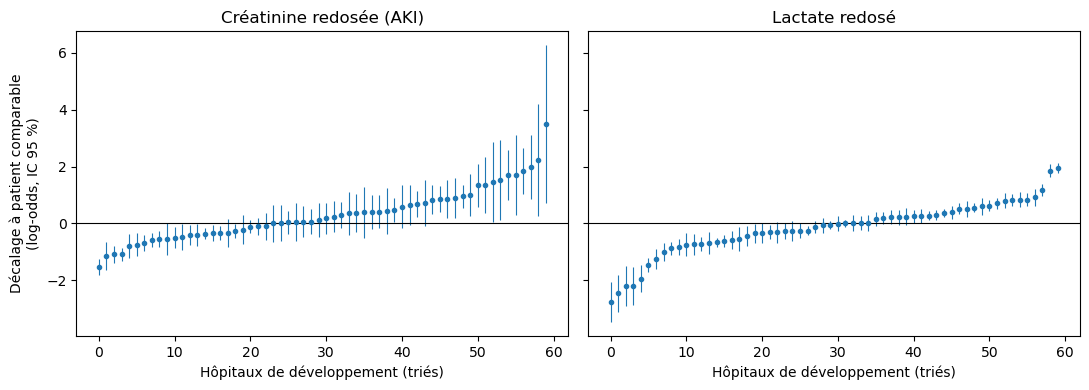

In [5]:
# ============================================================
# ÉTAPE 5 — PROPENSION D'OBSERVATION DU LABEL ET DÉCALAGE PAR HÔPITAL
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

def fit_lr(d, target, cols):
    X_ = FX.loc[d["stay_id"], cols].to_numpy()
    tr = (d["split"] == "train").to_numpy()
    mdl = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.1))
    mdl.fit(X_[tr], d[target].to_numpy()[tr].astype(int))
    return mdl.decision_function(X_), tr

def propensity_analysis(d, target, name):
    lp, tr = fit_lr(d, target, PHYS)                      # physiologie + statiques : « à patient comparable »
    lp_all, _ = fit_lr(d, target, list(FX.columns))       # + indicateurs d'observation des 24 h (descriptif)
    y = d[target].to_numpy().astype(int)
    auc = auroc(y[~tr], 1 / (1 + np.exp(-lp[~tr])))
    auc_all = auroc(y[~tr], 1 / (1 + np.exp(-lp_all[~tr])))
    rows = []
    for h, idx in d.groupby("hospitalid").indices.items():
        a, v = site_offset(lp[idx], y[idx])
        rows.append({"hospitalid": h, "n": len(idx), "taux_observe": y[idx].mean(), "decalage": a, "variance": v})
    off = pd.DataFrame(rows)
    re = random_effects(off["decalage"], off["variance"])
    mort = d.groupby(target)["y_mortality"].mean()
    return {"label": name, "n": len(d), "taux_redosage": y.mean(), "auroc_val_test": auc,
            "auroc_avec_observation_24h": auc_all, "tau": re["tau"], "I2": re["I2"], "Q_p": re["Q_pvalue"],
            "mortalite_si_redose": mort.get(True, np.nan), "mortalite_si_non_redose": mort.get(False, np.nan)}, off

P_cr = P[P["cr_base"].notna()].copy()
res_cr, off_cr = propensity_analysis(P_cr, "obs_cr", "créatinine (AKI)")
res_la, off_la = propensity_analysis(P.copy(), "obs_la", "lactate (hyperlactatémie)")
prop = pd.DataFrame([res_cr, res_la]).set_index("label")
prop.to_csv(RES_DIR / "propension_observation.csv")
off_cr.assign(label="creatinine").to_csv(RES_DIR / "decalages_creatinine.csv", index=False)
off_la.assign(label="lactate").to_csv(RES_DIR / "decalages_lactate.csv", index=False)
display(prop.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, off) in zip(axes, [("Créatinine redosée (AKI)", off_cr), ("Lactate redosé", off_la)]):
    o = off.sort_values("decalage").reset_index(drop=True)
    ci = 1.96 * np.sqrt(o["variance"])
    ax.errorbar(o.index, o["decalage"], yerr=ci, fmt="o", ms=3, lw=0.8, color="tab:blue")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(title); ax.set_xlabel("Hôpitaux de développement (triés)")
axes[0].set_ylabel("Décalage à patient comparable\n(log-odds, IC 95 %)")
plt.tight_layout(); plt.savefig(FIG_DIR / "decalages_par_hopital.png", dpi=200); plt.show()

## Étape 6 — Éclaircissement des dosages : le label change-t-il avec la seule politique ? (C3)

Les patients restent les mêmes ; seuls les dosages **après 24 h** sont retirés (les données d'entrée ne changent pas).

1. **Éclaircissement vers les hôpitaux qui dosent le moins (critère C3).** Les hôpitaux sont rangés en tiers selon leur intensité de dosage (dosages par jour de présence). Dans le tiers « haut », chaque dosage est conservé avec la probabilité r_bas / r_hôpital, de sorte que la fréquence rejoigne celle du tiers « bas ». 20 répétitions.
2. **Politiques à intervalle fixe** (courbe dose-réponse) : au plus un dosage toutes les H heures, appliqué à tous les hôpitaux.

Pour les patients initialement positifs, on distingue ceux qui deviennent **négatifs** (label erroné) et ceux qui deviennent **non évaluables** (label manquant).
Une politique à intervalle garde toujours au moins un dosage : elle ne crée pas de label manquant, seulement des pics manqués (la colonne `redosage` ne bouge pas).

Éclaircissement du tiers « haut » vers l'intensité du tiers « bas » :


label,creatinine,lactate
hopitaux_tiers_haut,20.0000,20.0000
hopitaux_tiers_bas,20.0000,20.0000
intensite_haut,1.3258,0.4053
intensite_bas,0.9981,0.0565
evenements_initiaux,540.0000,454.0000
evenements_apres,495.2500,154.0000
baisse_relative,0.0829,0.6608
baisse_relative_sd,0.0090,0.0195
positifs_devenus_negatifs,0.0734,0.1507
positifs_devenus_non_evaluables,0.0094,0.5101


Politiques à intervalle fixe (tous les hôpitaux) :


,label,politique,evenements,relatif,redosage
0,creatinine,observée,1518.0,1.0000,0.9589
1,creatinine,12 h,1491.0,0.9822,0.9589
2,creatinine,24 h,1408.0,0.9275,0.9589
3,creatinine,48 h,1083.0,0.7134,0.9589
4,creatinine,72 h,880.0,0.5797,0.9589
5,lactate,observée,943.0,1.0000,0.1614
6,lactate,12 h,900.0,0.9544,0.1614
7,lactate,24 h,855.0,0.9067,0.1614
8,lactate,48 h,781.0,0.8282,0.1614


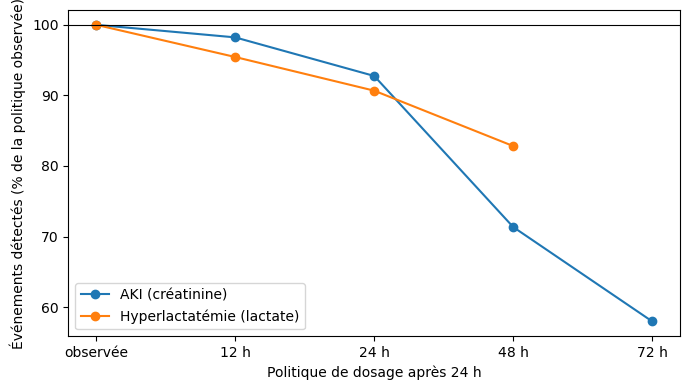

In [6]:
# ============================================================
# ÉTAPE 6 — ÉCLAIRCISSEMENT DES DOSAGES (C3)
# ============================================================
def evaluate(post_kept, d, kind):
    s = summarize_post(post_kept, d["stay_id"])
    if kind == "creatinine":
        obs, cc, neg = aki_labels(d["cr_base"], s["peak"], s["n_post"], AKI_RATIO)
    else:
        obs, cc, neg = threshold_labels(s["peak"], s["n_post"], LAC_THR)
    return obs, cc, neg

def thinning_analysis(d, kind, rate_col, obs_col, cc_col, neg_col):
    post = POST[kind][POST[kind]["stay_id"].isin(d["stay_id"])]
    r_h = d.groupby("hospitalid")[rate_col].mean()
    q1, q2 = r_h.quantile([1 / 3, 2 / 3])
    low, high = r_h.index[r_h <= q1], r_h.index[r_h >= q2]
    r_low = r_h.loc[low].mean()
    dh = d[d["hospitalid"].isin(high)].reset_index(drop=True)
    ph = post[post["stay_id"].isin(dh["stay_id"])]
    keep = np.minimum(1.0, r_low / ph["stay_id"].map(dh.set_index("stay_id")["hospitalid"]).map(r_h))
    pos0 = dh[cc_col].to_numpy() == 1
    n0 = np.nansum(dh[neg_col])
    rng = np.random.default_rng(SEED)
    reps = []
    for _ in range(N_REP):
        obs, cc, neg = evaluate(thin_bernoulli(ph, keep, rng), dh, kind)
        reps.append({"evenements": np.nansum(neg), "devenus_negatifs": float(np.mean((cc[pos0] == 0))),
                     "devenus_non_evaluables": float(np.mean(~obs[pos0])), "taux_redosage": float(np.mean(obs))})
    reps = pd.DataFrame(reps)
    bern = {"label": kind, "hopitaux_tiers_haut": len(high), "hopitaux_tiers_bas": len(low),
            "intensite_haut": float(r_h.loc[high].mean()), "intensite_bas": float(r_low),
            "evenements_initiaux": float(n0), "evenements_apres": float(reps["evenements"].mean()),
            "baisse_relative": float(1 - reps["evenements"].mean() / max(n0, 1)),
            "baisse_relative_sd": float(reps["evenements"].std() / max(n0, 1)),
            "positifs_devenus_negatifs": float(reps["devenus_negatifs"].mean()),
            "positifs_devenus_non_evaluables": float(reps["devenus_non_evaluables"].mean()),
            "redosage_avant": float(dh[obs_col].mean()), "redosage_apres": float(reps["taux_redosage"].mean())}
    curve = [{"label": kind, "politique": "observée", "evenements": float(np.nansum(d[neg_col])), "relatif": 1.0,
              "redosage": float(d[obs_col].mean())}]
    for H in POLICIES_H[kind]:
        obs, cc, neg = evaluate(thin_interval(post, H, start=WIN), d, kind)
        curve.append({"label": kind, "politique": f"{H} h", "evenements": float(np.nansum(neg)),
                      "relatif": float(np.nansum(neg) / max(np.nansum(d[neg_col]), 1)), "redosage": float(np.mean(obs))})
    return bern, pd.DataFrame(curve), r_h

b_cr, curve_cr, r_cr = thinning_analysis(P_cr, "creatinine", "cr_rate", "obs_cr", "aki_cc", "aki_neg")
b_la, curve_la, r_la = thinning_analysis(P.copy(), "lactate", "la_rate", "obs_la", "hyper_cc", "hyper_neg")
bern = pd.DataFrame([b_cr, b_la]).set_index("label")
curves = pd.concat([curve_cr, curve_la], ignore_index=True)
bern.to_csv(RES_DIR / "eclaircissement_tiers.csv"); curves.to_csv(RES_DIR / "eclaircissement_intervalles.csv", index=False)
print("Éclaircissement du tiers « haut » vers l'intensité du tiers « bas » :")
display(bern.T.round(4))
print("Politiques à intervalle fixe (tous les hôpitaux) :")
display(curves.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for kind, lab, col in [("creatinine", "AKI (créatinine)", "tab:blue"), ("lactate", "Hyperlactatémie (lactate)", "tab:orange")]:
    cu = curves[curves["label"] == kind]
    ax.plot(cu["politique"], 100 * cu["relatif"], "o-", color=col, label=lab)
ax.axhline(100, color="k", lw=0.8)
ax.set_ylabel("Événements détectés (% de la politique observée)"); ax.set_xlabel("Politique de dosage après 24 h")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "eclaircissement_dose_reponse.png", dpi=200); plt.show()

## Étape 7 — Les hôpitaux qui dosent plus trouvent-ils plus d'événements que prévu ? (C4)

Un modèle commun de l'événement (codage « non dosé = négatif ») à partir de la **physiologie et des variables statiques seulement** (sans indicateurs d'observation) donne un nombre attendu par hôpital.
On compare log(observé / attendu) à l'intensité de dosage de l'hôpital (corrélation de Spearman). Analyse observationnelle : elle complète l'étape 6, sans prouver la causalité.

,spearman_rho,p,hopitaux
label,,,
AKI (créatinine),0.3560,0.0052,60
hyperlactatémie (lactate),0.8291,0.0000,60


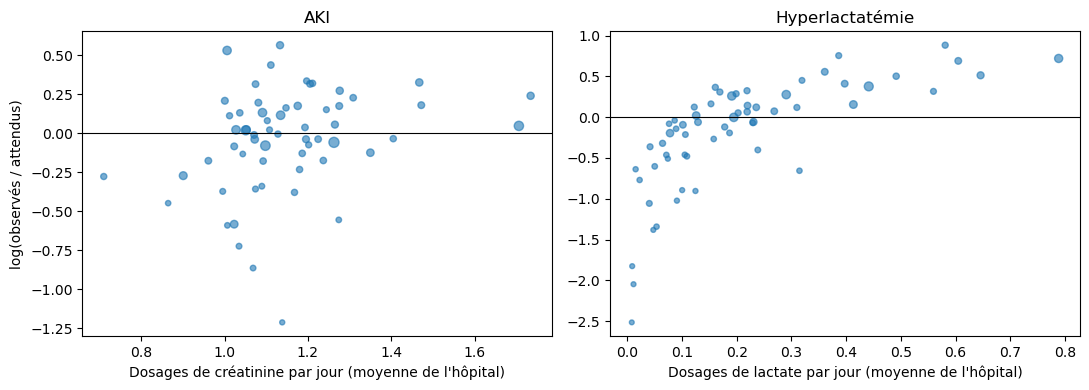

In [7]:
# ============================================================
# ÉTAPE 7 — ÉVÉNEMENTS OBSERVÉS / ATTENDUS ET INTENSITÉ DE DOSAGE (C4)
# ============================================================
from scipy import stats

def oe_analysis(d, neg_col, r_h, name):
    lp, tr = fit_lr(d, neg_col, PHYS)
    p = 1 / (1 + np.exp(-lp))
    g = pd.DataFrame({"hospitalid": d["hospitalid"].to_numpy(), "O": d[neg_col].to_numpy(), "E": p}).groupby("hospitalid").sum()
    g["log_O_E"] = np.log((g["O"] + 0.5) / (g["E"] + 0.5))
    g["intensite"] = r_h.reindex(g.index)
    rho = stats.spearmanr(g["intensite"], g["log_O_E"])
    return {"label": name, "spearman_rho": float(rho.statistic), "p": float(rho.pvalue), "hopitaux": len(g)}, g

oe_cr_res, oe_cr = oe_analysis(P_cr, "aki_neg", r_cr, "AKI (créatinine)")
oe_la_res, oe_la = oe_analysis(P.copy(), "hyper_neg", r_la, "hyperlactatémie (lactate)")
oe = pd.DataFrame([oe_cr_res, oe_la_res]).set_index("label")
oe.to_csv(RES_DIR / "observe_attendu_intensite.csv")
oe_cr.to_csv(RES_DIR / "oe_par_hopital_creatinine.csv"); oe_la.to_csv(RES_DIR / "oe_par_hopital_lactate.csv")
display(oe.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, g, xl) in zip(axes, [("AKI", oe_cr, "Dosages de créatinine par jour (moyenne de l'hôpital)"),
                                    ("Hyperlactatémie", oe_la, "Dosages de lactate par jour (moyenne de l'hôpital)")]):
    ax.scatter(g["intensite"], g["log_O_E"], s=12 + g["O"] / 2, alpha=0.6)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(title); ax.set_xlabel(xl)
axes[0].set_ylabel("log(observés / attendus)")
plt.tight_layout(); plt.savefig(FIG_DIR / "observe_attendu_intensite.png", dpi=200); plt.show()

## Étape 8 — Décision (critères fixés avant les résultats)

Rappel : **GO** = C1 et (C3 ou C4) ; **PARTIEL** = (C3 ou C4) sans C1 ; **NO-GO** sinon. C2 choisit le ou les mécanismes du notebook 05 ; C5 est descriptif.

In [8]:
# ============================================================
# ÉTAPE 8 — DÉCISION
# ============================================================
r = prop.loc["créatinine (AKI)"]; rl = prop.loc["lactate (hyperlactatémie)"]
C1 = bool(r["tau"] >= CRIT["C1_tau"] and r["Q_p"] < CRIT["C1_p"])
C2 = bool(r["auroc_val_test"] >= CRIT["C2_auroc"])
C3 = bool(bern.loc["creatinine", "baisse_relative"] >= CRIT["C3_drop"])
C4 = bool(oe.loc["AKI (créatinine)", "spearman_rho"] >= CRIT["C4_rho"] and oe.loc["AKI (créatinine)", "p"] < CRIT["C4_p"])
crit = pd.DataFrame([
    {"code": "C1", "critère": "dépendance au site (créatinine)", "valeur": f"τ = {r['tau']:.3f}, I² = {r['I2']:.2f}, Q p = {r['Q_p']:.2g}", "rempli": C1},
    {"code": "C2", "critère": "dépendance au patient (créatinine)", "valeur": f"AUROC = {r['auroc_val_test']:.3f}", "rempli": C2},
    {"code": "C3", "critère": "label sensible à la politique (éclaircissement)", "valeur": f"baisse = {bern.loc['creatinine', 'baisse_relative']:.1%} ± {bern.loc['creatinine', 'baisse_relative_sd']:.1%}", "rempli": C3},
    {"code": "C4", "critère": "observés / attendus suivent l'intensité", "valeur": f"ρ = {oe.loc['AKI (créatinine)', 'spearman_rho']:.2f}, p = {oe.loc['AKI (créatinine)', 'p']:.2g}", "rempli": C4},
    {"code": "C5", "critère": "lactate vs créatinine (descriptif)", "valeur": f"τ {rl['tau']:.2f} vs {r['tau']:.2f} ; AUROC {rl['auroc_val_test']:.2f} vs {r['auroc_val_test']:.2f} ; baisse {bern.loc['lactate', 'baisse_relative']:.1%} vs {bern.loc['creatinine', 'baisse_relative']:.1%}", "rempli": None},
])
display(crit)
mech = ("label manquant non aléatoire (cas complets biaisés) ET label erroné" if C2
        else "label erroné seulement (le redosage dépend peu du patient)")
if C1 and (C3 or C4):
    verdict = f"GO : l'observation du label dépend de l'hôpital et change le label -> notebook 05 (entraînement fédéré). Mécanisme(s) à traiter : {mech}."
elif (C3 or C4) and not C1:
    verdict = "PARTIEL : le label dépend de la politique de mesure, mais les hôpitaux se ressemblent ; l'intérêt fédéré est plus faible."
else:
    verdict = "NO-GO : le phénomène n'est pas assez marqué dans eICU pour justifier la méthode."
print("\nVERDICT :", verdict)

report = f"""# Rapport 04 — observation du label (sans entraînement)

Protocole `{protocol['hash']}` | {len(DEV)} hôpitaux de développement | présents à 48 h : {int(c['present48'].sum())} séjours

## Population
```
{flow.round(3).to_string()}
{summary.T.round(4).to_string()}
```
## Propension d'observation (C1, C2, C5)
```
{prop.round(4).to_string()}
```
## Éclaircissement (C3)
```
{bern.T.round(4).to_string()}
{curves.round(4).to_string(index=False)}
```
## Observés / attendus (C4)
```
{oe.round(4).to_string()}
```
## Critères
```
{crit.to_string(index=False)}
```
**Verdict : {verdict}**
"""
(RES_DIR / "rapport_04.md").write_text(report, encoding="utf-8")
crit.to_csv(RES_DIR / "criteres_04.csv", index=False)
print("Écrit :", (RES_DIR / "rapport_04.md").resolve())

,code,critère,valeur,rempli
0,C1,dépendance au site (créatinine),"τ = 0.607, I² = 0.89, Q p = 4.8e-77",True
1,C2,dépendance au patient (créatinine),AUROC = 0.726,True
2,C3,label sensible à la politique (éclaircissement),baisse = 8.3% ± 0.9%,False
3,C4,observés / attendus suivent l'intensité,"ρ = 0.36, p = 0.0052",True
4,C5,lactate vs créatinine (descriptif),τ 0.70 vs 0.61 ; AUROC 0.74 vs 0.73 ; baisse 66.1% vs 8.3%,None



VERDICT : GO : l'observation du label dépend de l'hôpital et change le label -> notebook 05 (entraînement fédéré). Mécanisme(s) à traiter : label manquant non aléatoire (cas complets biaisés) ET label erroné.
Écrit : C:\Users\Stryve\Desktop\StryveSolution\Imagerie-Phd\P.H.D\New Impl\FUALA-w_28-06-2026\OP-FL-V2\results\04_observation_label\rapport_04.md


## Étape 9 — Contrôles

La cellule échoue si un contrôle ne passe pas.

In [9]:
# ============================================================
# ÉTAPE 9 — CONTRÔLES
# ============================================================
checks = []
def check(name, ok):
    checks.append({"contrôle": name, "ok": bool(ok)})

check("Aucun hôpital du test verrouillé utilisé", LOCKED.isdisjoint(set(c["hospitalid"])))
check("Seuls les hôpitaux de développement", set(c["hospitalid"]) <= set(DEV))
check("Créatinine de base et pic identiques au notebook 01", same_extraction)
check(f"Label AKI proche du notebook 01 malgré la coupure à la sortie (accord {agree_aki:.2%} >= 98 %)", agree_aki >= 0.98)
ok_win = True
for kind, end in [("creatinine", AKI_END), ("lactate", LAC_END)]:
    pw = POST[kind]
    ok_win &= bool((pw["offset"] >= WIN).all() and (pw["offset"] <= np.minimum(pw["stay_id"].map(disc), end)).all())
check("Dosages après 24 h dans la fenêtre et avant la sortie de réanimation", ok_win)
mono = True   # politiques emboîtées (H2 multiple de H1) : les dosages gardés à H2 sont un sous-ensemble de ceux gardés à H1
for kind in ("creatinine", "lactate"):
    cu = curves[curves["label"] == kind].set_index("politique")["evenements"]
    Hs = POLICIES_H[kind]
    mono &= bool(all(cu[f"{H} h"] <= cu["observée"] + 1e-9 for H in Hs))
    mono &= bool(all(cu[f"{H2} h"] <= cu[f"{H1} h"] + 1e-9 for H1 in Hs for H2 in Hs if H2 > H1 and H2 % H1 == 0))
check("Moins de dosages => jamais plus d'événements détectés (politiques emboîtées)", mono)
pc = POST["creatinine"]
check("L'éclaircissement par intervalle ne fait que retirer des dosages",
      len(thin_interval(pc, 24, start=WIN)) <= len(pc) and set(thin_interval(pc, 24, start=WIN).index) <= set(pc.index))
check("Population « présents à 48 h » cohérente", bool((P["unitdischargeoffset"] >= PRESENT_MIN).all()))
res = pd.DataFrame(checks)
display(res)
if not res["ok"].all():
    raise AssertionError("Au moins un contrôle a échoué : voir le tableau ci-dessus.")
print("Tous les contrôles passent.")

,contrôle,ok
0,Aucun hôpital du test verrouillé utilisé,True
1,Seuls les hôpitaux de développement,True
2,Créatinine de base et pic identiques au notebook 01,True
3,Label AKI proche du notebook 01 malgré la coupure à la sortie (accord 99.48% >= 98 %),True
4,Dosages après 24 h dans la fenêtre et avant la sortie de réanimation,True
5,Moins de dosages => jamais plus d'événements détectés (politiques emboîtées),True
6,L'éclaircissement par intervalle ne fait que retirer des dosages,True
7,Population « présents à 48 h » cohérente,True


Tous les contrôles passent.
